In [18]:
import kagglehub
import os
import pandas as pd 
import seaborn as sns

path = kagglehub.dataset_download("arashnic/time-series-forecasting-with-yahoo-stock-price")
 
print("Path to dataset files:", path)
# 3. Ver la lista de archivos CSV que contiene la carpeta
archivos = os.listdir(path)
print(archivos)
 
ruta_application_train = os.path.join(path, 'yahoo_stock.csv')
 
df = pd.read_csv(ruta_application_train, sep=',')

df.head()
 

Path to dataset files: C:\Users\USUARIO\.cache\kagglehub\datasets\arashnic\time-series-forecasting-with-yahoo-stock-price\versions\3
['yahoo_stock.csv']


,Date,High,Low,Open,Close,Volume,Adj Close
0,2015-11-23,2095.610107,2081.389893,2089.409912,2086.590088,3.587980e+09,2086.590088
1,2015-11-24,2094.120117,2070.290039,2084.419922,2089.139893,3.884930e+09,2089.139893
2,2015-11-25,2093.000000,2086.300049,2089.300049,2088.870117,2.852940e+09,2088.870117
3,2015-11-26,2093.000000,2086.300049,2089.300049,2088.870117,2.852940e+09,2088.870117
4,2015-11-27,2093.290039,2084.129883,2088.820068,2090.110107,1.466840e+09,2090.110107


In [21]:
df = df[['Date', 'Open']]
df.head()

,Date,Open
0,2015-11-23,2089.409912
1,2015-11-24,2084.419922
2,2015-11-25,2089.300049
3,2015-11-26,2089.300049
4,2015-11-27,2088.820068


# Graficar serie de tiempo

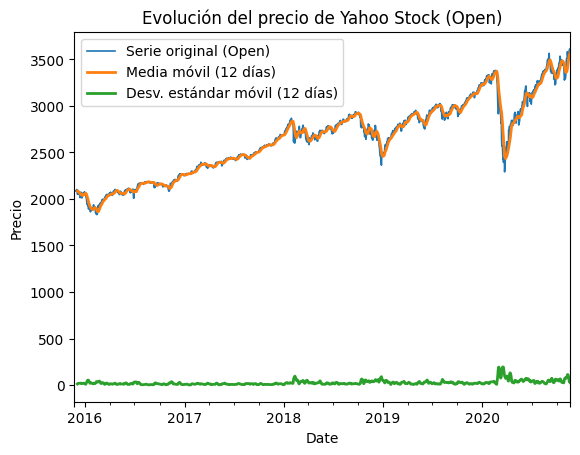

In [22]:
import matplotlib.pyplot as plt


# Asegurar que la columna 'Date' sea datetime y establecerla como índice
df['Date'] = pd.to_datetime(df['Date'])
df_idx = df.set_index('Date')
 
# Seleccionamos la columna 'Open' para la visualización de la serie temporal
serie = df_idx['Open']
 
fig, ax = plt.subplots()
serie.plot(ax=ax, label="Serie original (Open)", linewidth=1.2)
serie.rolling(12).mean().plot(ax=ax, label="Media móvil (12 días)", linewidth=2)
serie.rolling(12).std().plot(ax=ax, label="Desv. estándar móvil (12 días)", linewidth=2)
ax.set_title("Evolución del precio de Yahoo Stock (Open)")
ax.set_ylabel("Precio")
ax.legend()
plt.show()
 

In [30]:
df_idx.head()

,Open
Date,
2015-11-23,2089.409912
2015-11-24,2084.419922
2015-11-25,2089.300049
2015-11-26,2089.300049
2015-11-27,2088.820068


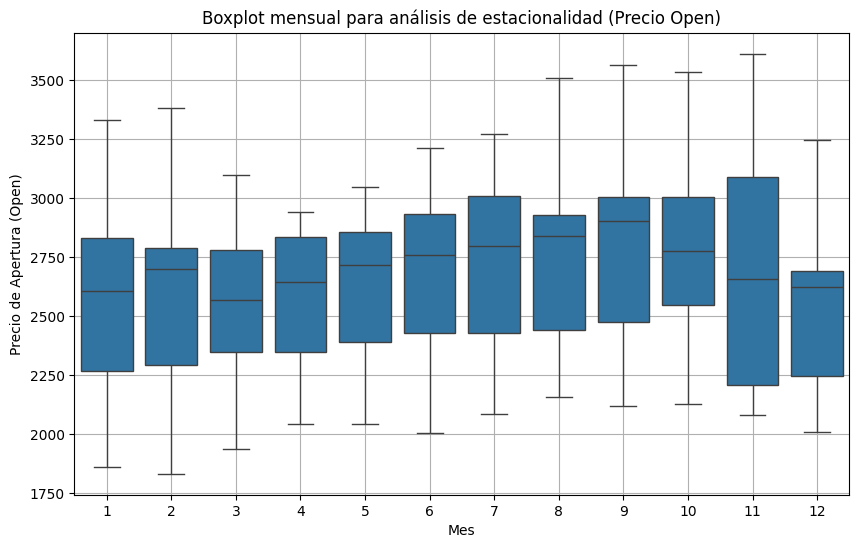

In [32]:
# 1. Usar 'Date' (con mayúscula) y extraer el mes
df['month'] = df['Date'].dt.month

# 2. Visualización: Boxplot por mes usando 'Open' (con mayúscula)
plt.figure(figsize=(10, 6))
sns.boxplot(x='month', y='Open', data=df)
plt.title('Boxplot mensual para análisis de estacionalidad (Precio Open)')
plt.xlabel('Mes')
plt.ylabel('Precio de Apertura (Open)')
plt.grid(True)
plt.show()